# Unrotated surface code: memory and surgery

The unrotated (planar) surface code through the SED pipeline: the patch
(`unrotated_surface_code`), circuit-based memory (`memory_unrotated_circuit`)
and two-patch lattice surgery (`surgery_unrotated_circuit`), each next to its
rotated counterpart. Both builders schedule with `UnrotatedSurfaceCodeSchedule`.

In [20]:
%matplotlib widget 
import matplotlib.pyplot as plt
import numpy as np
import pymatching

from dizx import builders as B
from dizx.code import rotated_surface_code, unrotated_surface_code
from dizx.dem_view import graphlike_distance
from dizx.noise_models import NoiseSpec, apply_tagged_noise_model

## The patch

Data qubits where `x + y` is even, generators where it is odd. Weight-3 X
generators sit on the top/bottom boundaries before rotation; the builders use
`rotation=90` so that they match the rotated memory's orientation.

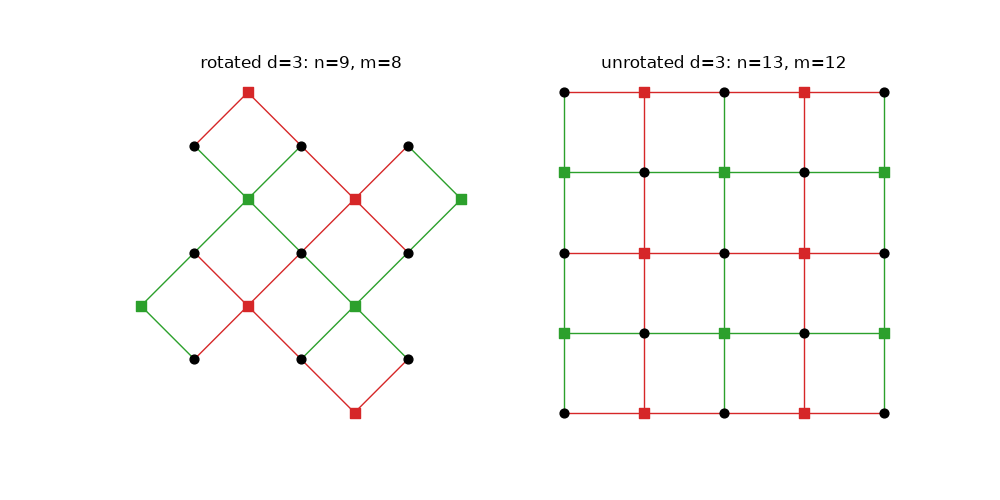

In [21]:
def draw_code(code, ax, title):
    colour = {"X": "tab:green", "Z": "tab:red"}
    for s, (x, y) in zip(code.stabilisers, code.stabiliser_positions):
        c = colour[next(iter(s.values()))]
        for qx, qy in s:
            ax.plot([x, qx], [y, qy], color=c, lw=1, zorder=1)
        ax.scatter(x, y, color=c, marker="s", s=60, zorder=2)
    ax.scatter(*zip(*code.qubits), color="black", s=40, zorder=3)
    ax.set_aspect("equal")
    ax.set_title(f"{title}: n={code.n}, m={len(code.stabilisers)}")
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(10, 5))
draw_code(rotated_surface_code(3, rotation=90), axes[0], "rotated d=3")
draw_code(unrotated_surface_code(3, rotation=90), axes[1], "unrotated d=3")
plt.show()

## Memory

`memory_unrotated_circuit(d, n_cycles, observable)` is `memory_circuit` on the
unrotated patch: `4 n + 1` SED layers, starting and ending with the type other
than the observable.

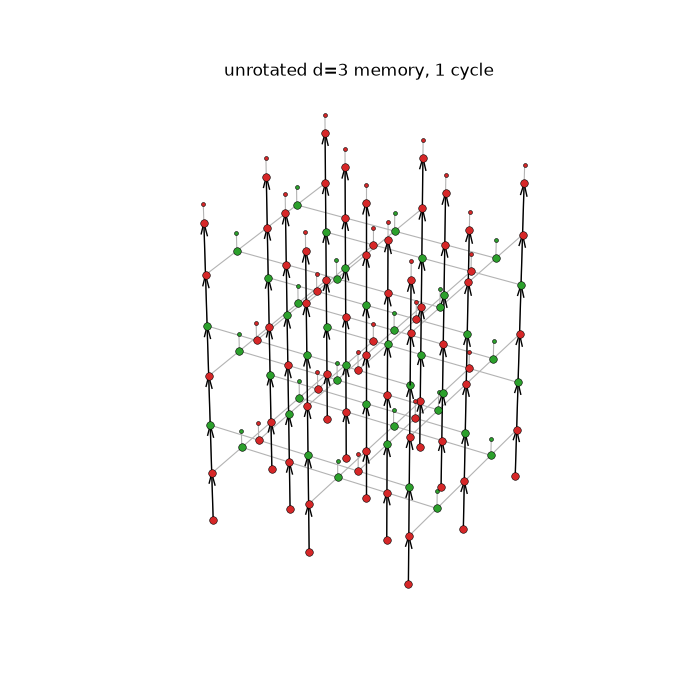

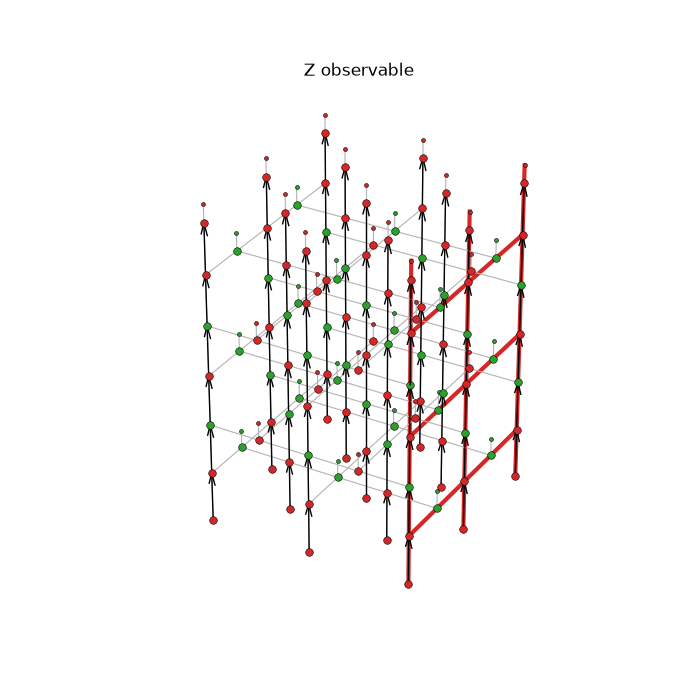

In [22]:
mem = B.BUILDERS["memory_unrotated_circuit"](3, 1, "Z")
mem.experiment.draw(title="unrotated d=3 memory, 1 cycle")
plt.show()
mem.experiment.draw(mem.experiment.observables[0], title="Z observable")
plt.show()

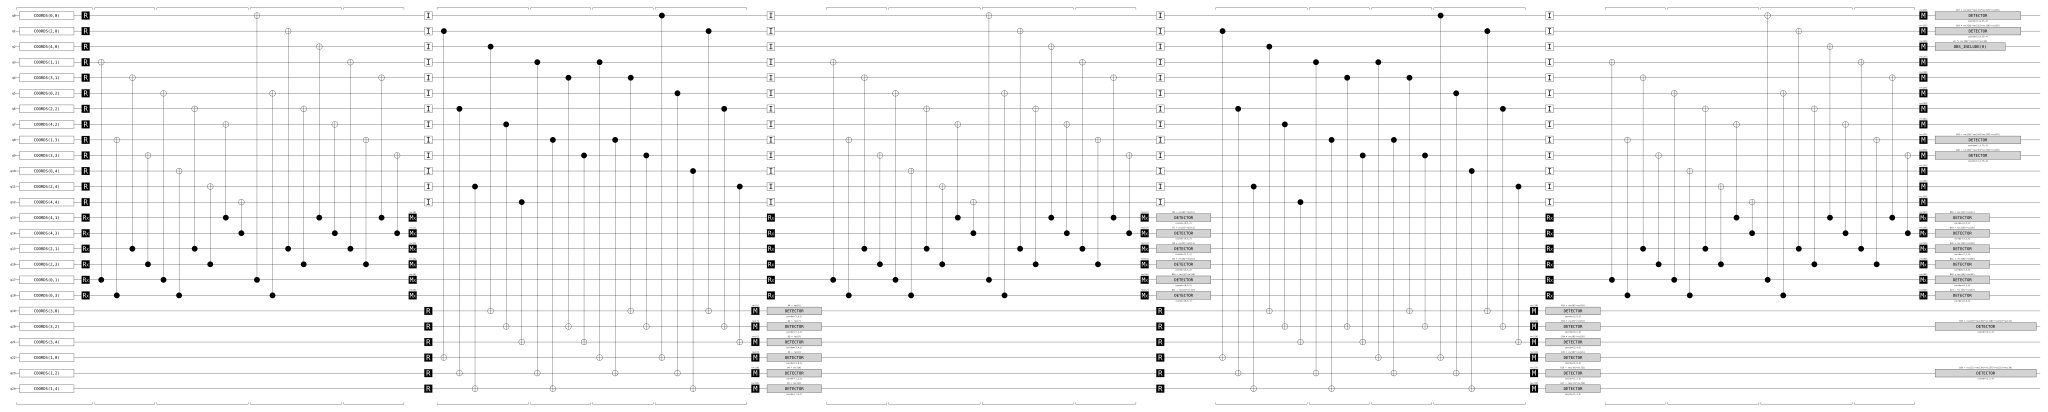

In [23]:
mem.circuit.diagram("timeline-svg")

Circuit-level noise from the tagged noise model, the same channels as the
paper's circuit noise. Both bases reach full graphlike distance.

In [24]:
def circuit_noise(p):
    return {("circuit", "reset"): NoiseSpec("RESET_FLIP", p),
            ("circuit", "single_qubit_gate"): NoiseSpec("DEPOLARIZE1", p),
            ("circuit", "two_qubit_gate"): NoiseSpec("DEPOLARIZE2", p),
            ("circuit", "single_qubit_measurement"): NoiseSpec("MEASUREMENT_FLIP", p)}


rows = []
for name in ("memory_circuit", "memory_unrotated_circuit"):
    for d in (3, 5):
        for basis in "XZ":
            c = B.BUILDERS[name](d, d, basis).circuit
            rows.append((name, d, basis, c.num_qubits, c.num_detectors,
                         graphlike_distance(c, circuit_noise(1e-3))))
print(f"{'builder':26} d basis qubits detectors distance")
for r in rows:
    print(f"{r[0]:26} {r[1]} {r[2]:>5} {r[3]:>6} {r[4]:>9} {r[5]:>8}")

builder                    d basis qubits detectors distance
memory_circuit             3     X     17        52        3
memory_circuit             3     Z     17        52        3
memory_circuit             5     X     49       252        5
memory_circuit             5     Z     49       252        5
memory_unrotated_circuit   3     X     25        78        3
memory_unrotated_circuit   3     Z     25        78        3
memory_unrotated_circuit   5     X     81       420        5
memory_unrotated_circuit   5     Z     81       420        5


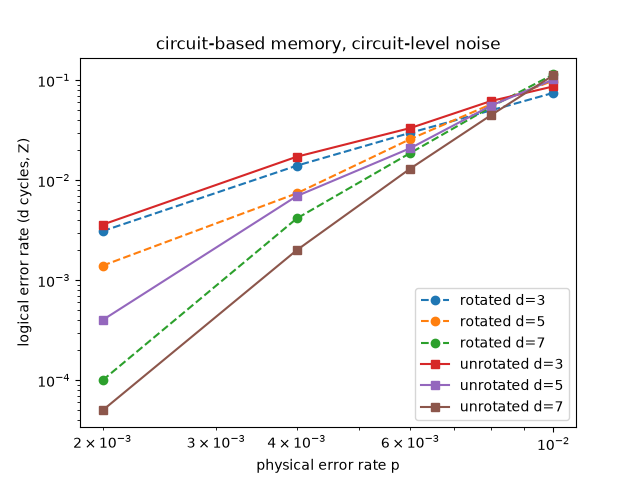

In [25]:
def logical_error_rate(c, shots):
    dem = c.detector_error_model(decompose_errors=True)
    dets, obs = c.compile_detector_sampler().sample(shots, separate_observables=True)
    pred = pymatching.Matching.from_detector_error_model(dem).decode_batch(dets)
    return np.mean(np.any(pred != obs, axis=1))

fig, ax = plt.subplots()
ps = [0.002, 0.004, 0.006, 0.008, 0.01]
shots = 20_000
for name, style in (("memory_circuit", "o--"), ("memory_unrotated_circuit", "s-")):
    for d in (3, 5, 7):
        c = B.BUILDERS[name](d, d, "Z").circuit
        rates = [logical_error_rate(apply_tagged_noise_model(c, noise_by_type=circuit_noise(p)), shots)
                 for p in ps]
        ax.loglog(ps, rates, style, label=f"{'unrotated' if 'unrotated' in name else 'rotated'} d={d}")
        
ax.set_xlabel("physical error rate p")
ax.set_ylabel("logical error rate (d cycles, Z)")
ax.set_title("circuit-based memory, circuit-level noise")
ax.legend()
plt.show()

## Surgery

`two_patch_surgery(d, joint, unrotated=True)` places two `2d - 1`-wide patches
with the right one at `x = 2d`. The seam column `x = 2d - 1` holds `d - 1` new
data qubits and `d` new generators of the joint's type, so the merged patch is
an unrotated code of distance `2d` along the seam axis (rotated: `d` seam qubits,
merged distance `2d + 1`).

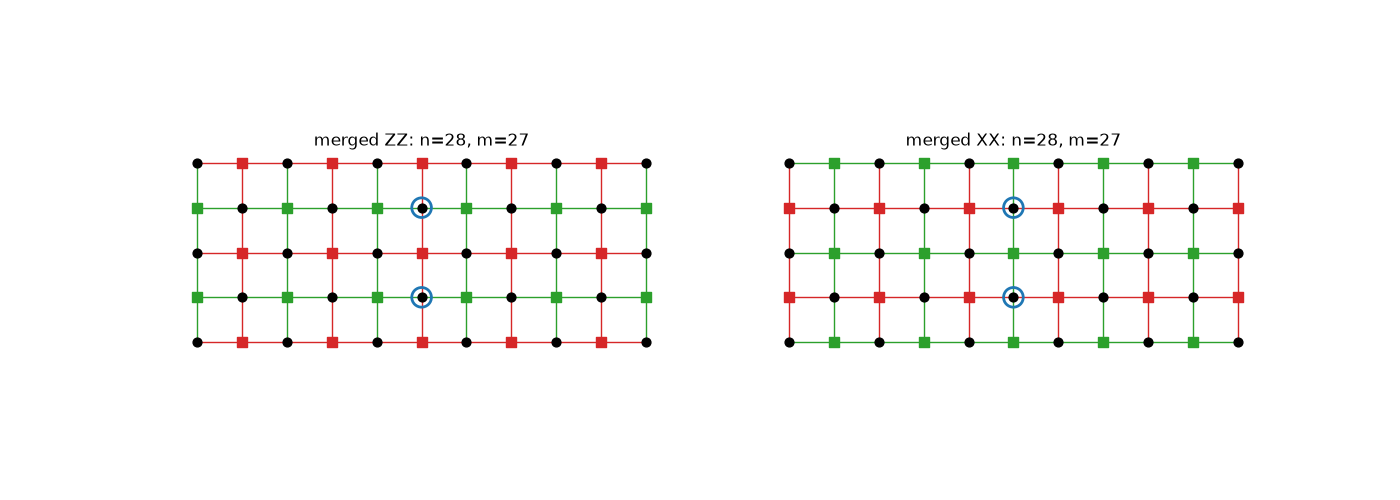

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, joint in zip(axes, ("ZZ", "XX")):
    s = B.build_surgery_unrotated_circuit(3, 1, joint, joint).surgery
    draw_code(s.merged, ax, f"merged {joint}")
    ax.scatter(*zip(*s.seam), facecolor="none", edgecolor="tab:blue", s=200, lw=2, zorder=4)
plt.show()

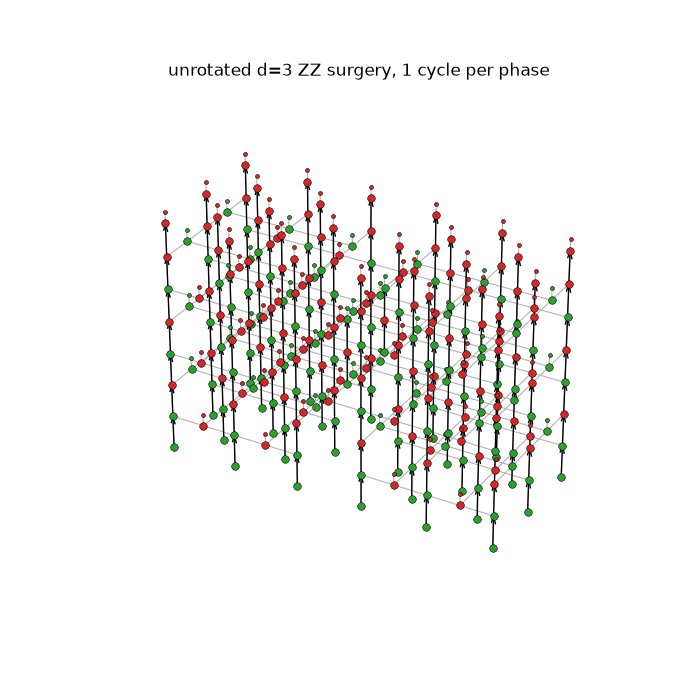

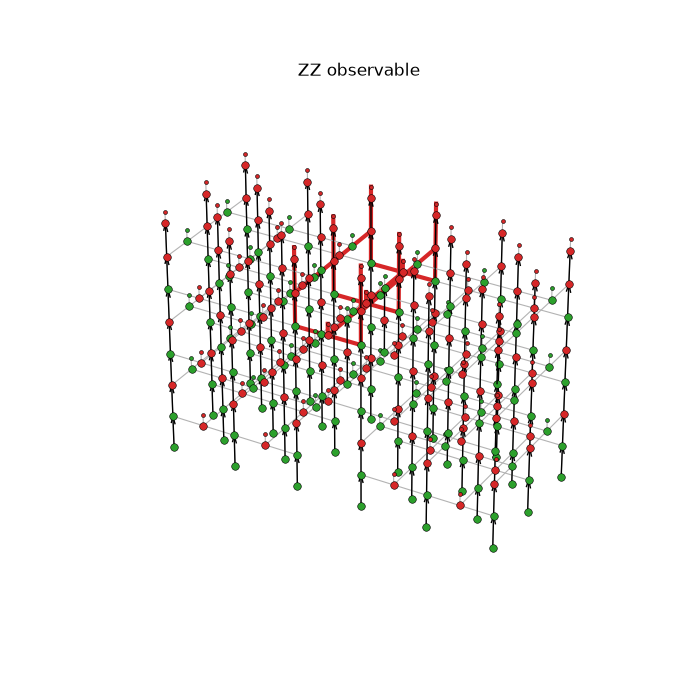

In [27]:
surg = B.build_surgery_unrotated_circuit(3, 1, "ZZ", "ZZ")
exp = surg.experiment
exp.draw(title="unrotated d=3 ZZ surgery, 1 cycle per phase")
plt.show()
exp.draw(exp.observables[0], title="ZZ observable")
plt.show()

In [28]:
rows = []
for name in ("surgery_circuit", "surgery_unrotated_circuit"):
    for merge in ("ZZ", "XX"):
        for obs in ("ZZ", "XX"):
            b = B.BUILDERS[name](3, 3, merge, obs)
            rows.append((name, merge, obs, b.circuit.num_qubits, len(b.surgery.seam),
                         graphlike_distance(b.circuit, circuit_noise(1e-3))))
print(f"{'builder':26} merge obs qubits seam distance")
for r in rows:
    print(f"{r[0]:26} {r[1]:>5} {r[2]:>3} {r[3]:>6} {r[4]:>4} {r[5]:>8}")

builder                    merge obs qubits seam distance
surgery_circuit               ZZ  ZZ     41    3        3
surgery_circuit               ZZ  XX     41    3        3
surgery_circuit               XX  ZZ     41    3        3
surgery_circuit               XX  XX     41    3        3
surgery_unrotated_circuit     ZZ  ZZ     55    2        3
surgery_unrotated_circuit     ZZ  XX     55    2        3
surgery_unrotated_circuit     XX  ZZ     55    2        3
surgery_unrotated_circuit     XX  XX     55    2        3


In [ ]:
fig, ax = plt.subplots()
for name, style in (("surgery_circuit", "o--"), ("surgery_unrotated_circuit", "s-")):
    for d in (3, 5):
        c = B.BUILDERS[name](d, d, "ZZ", "ZZ").circuit
        rates = [logical_error_rate(apply_tagged_noise_model(c, noise_by_type=circuit_noise(p)), shots)
                 for p in ps]
        ax.loglog(ps, rates, style, label=f"{'unrotated' if 'unrotated' in name else 'rotated'} d={d}")
ax.set_xlabel("physical error rate p")
ax.set_ylabel("logical error rate (ZZ outcome)")
ax.set_title("ZZ surgery, d cycles per phase, circuit-level noise")
ax.legend()
plt.show()

UnsupportedError: Axes3D does not support 'loglog'. Use ax.set_xscale/set_yscale/set_zscale and ax.plot(...) instead.